# Análisis experimental de MarianMT para traducción automática mediante tensores, logits y mapas de autoatención
:Artículo: Vaswani et al. (2017).
Se estudia MarianMT preentrenado en traducción inglés-español. No es el checkpoint
original: conserva encoder, decoder, atención escalada y posiciones sinusoidales,
pero cambia corpus, vocabulario y activación (Swish). Todos los números se calculan.

## 1 Instalación y configuración del entorno
**Objetivo:** fijar un entorno compatible. **Teoría:** versiones y pesos forman parte
del experimento. En Colab ejecutar la celda de instalación y reiniciar el kernel si
ya se habían importado estas bibliotecas. Python 3.12 fue la versión local usada.
**Verificación:** la sección 3 imprime las versiones efectivamente importadas.
**Interpretación:** una semilla no garantiza igualdad entre plataformas.

In [1]:
# En Jupyter/Colab descomentar esta línea antes de importar y reiniciar si procede:
# %pip install torch==2.6.0 transformers==4.46.3 numpy==1.26.4 pandas==2.2.3 matplotlib==3.9.2 sentencepiece==0.2.0 sacremoses==0.1.1

## 2 Importación de librerías
**Objetivo:** importar cálculo, modelo y gráficos. Se usa la API MarianMT explícita
y atención eager para recuperar pesos, evitando depender de kernels que no los
devuelven. **Verificación:** no debe haber errores de importación.
**Interpretación:** los resultados se exportan a JSON, CSV y NPZ, además de figuras.

In [2]:
import os, json, random, platform, sys, hashlib, importlib.metadata, time
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from transformers import MarianMTModel, MarianTokenizer

OUT = Path('resultados')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 130})

def save_json(name, data):
    (OUT/name).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')

def describe(x):
    a = x.detach().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)
    z = a.astype(np.float64).ravel()
    assert np.isfinite(z).all()
    return dict(shape=list(a.shape), dtype=str(a.dtype),
                device=str(x.device) if isinstance(x, torch.Tensor) else 'cpu',
                n=int(z.size), min=float(z.min()), max=float(z.max()),
                mean=float(z.mean()), std_population=float(z.std(ddof=0)),
                percentiles=dict(zip(['p0','p25','p50','p75','p100'],
                                     np.percentile(z,[0,25,50,75,100]).tolist())))

def figure_save(name):
    plt.tight_layout()
    plt.savefig(OUT/name, bbox_inches='tight')
    plt.show()
    plt.close()

## 3 Configuración de semillas y reproducibilidad
**Objetivo:** fijar las fuentes de variación. Se emplea CPU, float32 y un hilo para
facilitar la réplica sin GPU. `eval()` desactiva dropout; `inference_mode()` evita
autograd, pero no cambia `requires_grad`. **Verificación:** inspeccionar entorno.json.
**Interpretación:** se conservan versiones, plataforma, revisión y hashes.

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
MODEL_ID = 'Helsinki-NLP/opus-mt-en-es'
REVISION = '5bc4493d463cf000c1f0b50f8d56886a392ed4ab'

def get_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return 'not_installed'

env = dict(python=sys.version, platform=platform.platform(), processor=platform.processor(),
           versions={p: get_version(p) for p in
                     ['torch','transformers','numpy','pandas','matplotlib','sentencepiece','sacremoses']},
           seed=SEED, device=str(DEVICE), threads=torch.get_num_threads(),
           dtype='float32', deterministic=True, model_id=MODEL_ID, revision=REVISION,
           executed_utc=datetime.now(timezone.utc).isoformat())
print(json.dumps(env, indent=2))
save_json('entorno.json', env)

{
  "python": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "versions": {
    "torch": "2.11.0+cpu",
    "transformers": "5.20.2",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0",
    "sentencepiece": "0.2.2",
    "sacremoses": "not_installed"
  },
  "seed": 42,
  "device": "cpu",
  "threads": 1,
  "dtype": "float32",
  "deterministic": true,
  "model_id": "Helsinki-NLP/opus-mt-en-es",
  "revision": "5bc4493d463cf000c1f0b50f8d56886a392ed4ab",
  "executed_utc": "2026-10-29T08:18:06.812856+00:00"
}


## 4 Carga del modelo preentrenado
**Objetivo:** cargar pesos reales e inmutables. Se utiliza la copia local si está
disponible; en Colab se descarga la misma revisión. **Verificación:** la carga
falla si faltan pesos; no se crea un modelo aleatorio como alternativa.
**Interpretación:** la revisión identifica el artefacto, no la versión de Transformers.

In [5]:
LOCAL = Path('model')
if not (LOCAL/'pytorch_model.bin').exists() and (Path('../model')/'pytorch_model.bin').exists():
    LOCAL = Path('../model')
source = str(LOCAL) if (LOCAL/'pytorch_model.bin').exists() else MODEL_ID
kwargs = dict(local_files_only=True) if source != MODEL_ID else dict(revision=REVISION)
tokenizer = MarianTokenizer.from_pretrained(source, **kwargs)
model = MarianMTModel.from_pretrained(source, attn_implementation='eager', **kwargs)
model = model.to(DEVICE).float().eval()
c = model.config
assert c.is_encoder_decoder and c.d_model % c.encoder_attention_heads == 0
if source != MODEL_ID:
    hashes = json.loads((LOCAL/'sha256.json').read_text())
    for name, expected in hashes.items():
        assert hashlib.sha256((LOCAL/name).read_bytes()).hexdigest() == expected
    save_json('pesos_sha256.json', hashes)
save_json('configuracion.json', c.to_dict())
save_json('generacion_original.json', model.generation_config.to_dict())
print(type(model).__name__, 'revisión', REVISION)

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

MarianMTModel revisión 5bc4493d463cf000c1f0b50f8d56886a392ed4ab


## 5 Inspección de arquitectura e hiperparámetros
**Objetivo:** contar parámetros sin duplicar pesos compartidos y mostrar las capas.
`named_parameters()` elimina duplicados; posiciones sinusoidales son parámetros
registrados no entrenables. **Verificación:** la suma del inventario coincide con
el total. **Interpretación:** número de parámetros no es número de hiperparámetros;
estos últimos dependen de qué decisiones de configuración se enumeren.

In [6]:
params = pd.DataFrame([dict(name=n, shape=str(list(p.shape)), n=p.numel(),
                           trainable=p.requires_grad) for n,p in model.named_parameters()])
params.to_csv(OUT/'parametros.csv', index=False)
totals = dict(total=sum(p.numel() for p in model.parameters()),
              trainable=sum(p.numel() for p in model.parameters() if p.requires_grad),
              nontrainable=sum(p.numel() for p in model.parameters() if not p.requires_grad),
              optimized_this_experiment=0)
assert int(params.n.sum()) == totals['total']
save_json('conteo_parametros.json', totals)
(OUT/'model_summary.txt').write_text(str(model), encoding='utf-8')
blocks = []
for side in ['encoder','decoder']:
    for i, block in enumerate(getattr(model.model,side).layers):
        blocks.append(dict(component=side, layer=i+1,
                           parameters=sum(p.numel() for p in block.parameters()),
                           hidden=c.d_model,
                           heads=getattr(c,f'{side}_attention_heads'),
                           ffn=getattr(c,f'{side}_ffn_dim')))
blocks = pd.DataFrame(blocks)
blocks.to_csv(OUT/'capas.csv', index=False)
fields = ['encoder_layers','decoder_layers','d_model','encoder_attention_heads',
          'decoder_attention_heads','encoder_ffn_dim','decoder_ffn_dim','vocab_size',
          'max_position_embeddings','activation_function','scale_embedding',
          'share_encoder_decoder_embeddings','tie_word_embeddings','dropout',
          'attention_dropout','activation_dropout','encoder_layerdrop','decoder_layerdrop',
          'pad_token_id','eos_token_id','decoder_start_token_id']
hyper = {k:getattr(c,k,None) for k in fields}
save_json('hiperparametros.json',hyper)
print(totals)
print(blocks.to_string(index=False))
print(json.dumps(hyper,indent=2))

{'total': 77943296, 'trainable': 77943296, 'nontrainable': 0, 'optimized_this_experiment': 0}
component  layer  parameters  hidden  heads  ffn
  encoder      1     3152384     512      8 2048
  encoder      2     3152384     512      8 2048
  encoder      3     3152384     512      8 2048
  encoder      4     3152384     512      8 2048
  encoder      5     3152384     512      8 2048
  encoder      6     3152384     512      8 2048
  decoder      1     4204032     512      8 2048
  decoder      2     4204032     512      8 2048
  decoder      3     4204032     512      8 2048
  decoder      4     4204032     512      8 2048
  decoder      5     4204032     512      8 2048
  decoder      6     4204032     512      8 2048
{
  "encoder_layers": 6,
  "decoder_layers": 6,
  "d_model": 512,
  "encoder_attention_heads": 8,
  "decoder_attention_heads": 8,
  "encoder_ffn_dim": 2048,
  "decoder_ffn_dim": 2048,
  "vocab_size": 65001,
  "max_position_embeddings": 512,
  "activation_function": "sw

## 6 Preparación de ejemplos
**Objetivo:** comparar dos entradas con intercambio de roles y léxico similar.
Se ha determinado un contexto de una institución financiera. Se intercambian
bank y company para estudiar orden y roles. Las traducciones orientativas no se
introducen al modelo. No hay evaluación BLEU; son dos estudios de caso.
**Verificación:** se conservan las cadenas exactas. **Interpretación:** cualquier
diferencia es descriptiva y no permite atribuir causalmente una función a una cabeza.

In [7]:
texts = [
    'The bank contacted the company because it needed confirmation of the payment.',
    'The company contacted the bank because it needed confirmation of the payment.'
]
save_json('ejemplos.json', texts)
print(texts)

['The bank contacted the company because it needed confirmation of the payment.', 'The company contacted the bank because it needed confirmation of the payment.']


## 7 Extracción y análisis del tensor de entrada
**Objetivo:** distinguir texto, identificadores discretos y activaciones continuas.
MarianTokenizer aplica SentencePiece y añade EOS; se guardan tokens, IDs y máscara.
Se captura con un hook el tensor que entra en la primera self-attention del encoder,
que ya incorpora embeddings escalados y posición. Los IDs son categorías: su media
no representa significado. **Verificación:** límites del vocabulario y máscara uno.
**Interpretación:** [B,S] indexa una tabla; [B,S,d] contiene representaciones reales.

In [8]:
encoded = [tokenizer(t,return_tensors='pt',padding=False,truncation=False).to(DEVICE) for t in texts]
results = []
for i,batch in enumerate(encoded,1):
    ids = batch['input_ids']
    assert ids.min() >= 0 and ids.max() < c.vocab_size
    assert ids.shape[1] <= c.max_position_embeddings
    assert torch.all(batch['attention_mask'] == 1)
    tok = tokenizer.convert_ids_to_tokens(ids[0].tolist())
    pd.DataFrame(dict(position=range(len(tok)),token=tok,id=ids[0].tolist(),
                      mask=batch['attention_mask'][0].tolist())).to_csv(OUT/f'e{i}_tokens.csv',index=False)
    result = dict(example=i,text=texts[i-1],tokens=tok,ids=ids.tolist(),
                  mask=batch['attention_mask'].tolist(),input_stats=describe(ids),
                  mask_stats=describe(batch['attention_mask']))
    results.append(result)
    print('Ejemplo',i, result)

Ejemplo 1 {'example': 1, 'text': 'The bank contacted the company because it needed confirmation of the payment.', 'tokens': ['▁The', '▁bank', '▁contacted', '▁the', '▁company', '▁because', '▁it', '▁needed', '▁confirmation', '▁of', '▁the', '▁payment', '.', '</s>'], 'ids': [[42, 5008, 28442, 5, 1447, 414, 48, 1842, 15277, 7, 5, 3697, 3, 0]], 'mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], 'input_stats': {'shape': [1, 14], 'dtype': 'int64', 'device': 'cpu', 'n': 14, 'min': 0.0, 'max': 28442.0, 'mean': 4016.9285714285716, 'std_population': 7841.484457352317, 'percentiles': {'p0': 0.0, 'p25': 5.5, 'p50': 231.0, 'p75': 3233.25, 'p100': 28442.0}}, 'mask_stats': {'shape': [1, 14], 'dtype': 'int64', 'device': 'cpu', 'n': 14, 'min': 1.0, 'max': 1.0, 'mean': 1.0, 'std_population': 0.0, 'percentiles': {'p0': 1.0, 'p25': 1.0, 'p50': 1.0, 'p75': 1.0, 'p100': 1.0}}}
Ejemplo 2 {'example': 2, 'text': 'The company contacted the bank because it needed confirmation of the payment.', 'tokens': ['▁The'

## 8 Ejecución de inferencia
**Objetivo:** generar de forma autoregresiva y auditable. Cada llamada recibe el
prefijo generado y obtiene logits sin procesar mediante `.logits[:, -1, :]`.
Se selecciona argmax, prohibiendo únicamente PAD como salida; se termina en EOS
o a los 40 tokens. El PAD inicial es un marcador válido y NO se enmascara en decoder.
**Verificación:** cada token coincide con argmax permitido. No hay muestreo, beams,
temperatura ni EOS forzado. **Interpretación:** la salida es traducción condicionada
por el encoder. Las filas de logits predicen el token que sigue al prefijo de destino.

In [18]:
MAX_NEW_TOKENS = 40
all_outputs = []

# Limpiar hooks anteriores que puedan estar registrados y causar KeyError
try:
    model.model.encoder.layers[0].self_attn._forward_pre_hooks.clear()
except Exception:
    pass

for i,(batch,r) in enumerate(zip(encoded,results),1):
    prefix = torch.tensor([[c.decoder_start_token_id]], device=DEVICE)
    steps = []
    start = time.perf_counter()
    with torch.inference_mode():
        enc = model.model.encoder(**batch, return_dict=True)
        for _ in range(MAX_NEW_TOKENS):
            output = model(encoder_outputs=enc, attention_mask=batch['attention_mask'],
                           decoder_input_ids=prefix, use_cache=False, return_dict=True)
            raw = output.logits[:,-1,:].clone()
            assert torch.isfinite(raw).all()
            steps.append(raw)
            allowed = raw.clone()
            allowed[:,c.pad_token_id] = -torch.inf
            token = allowed.argmax(-1,keepdim=True)
            prefix = torch.cat([prefix,token],dim=1)
            if int(token.item()) == c.eos_token_id:
                break
        decoder_input = prefix[:,:-1]
        captured = {}
        def capture_input(module,args,kwargs):
            # Extraer de forma robusta de args o kwargs
            hidden_states = args[0] if len(args) > 0 else kwargs.get('hidden_states')
            captured['encoder_input'] = hidden_states.detach().clone()
        handle = model.model.encoder.layers[0].self_attn.register_forward_pre_hook(capture_input,with_kwargs=True)
        out = model(**batch,decoder_input_ids=decoder_input,use_cache=False,
                    output_attentions=True,output_hidden_states=True,return_dict=True)
        handle.remove()
        step_logits = torch.stack(steps,dim=1)
        assert torch.allclose(out.logits,step_logits,atol=1e-4,rtol=1e-5)
        allowed_all = out.logits.clone()
        allowed_all[:,:,c.pad_token_id] = -torch.inf
        assert torch.equal(allowed_all.argmax(-1),prefix[:,1:])
    r.update(generated_ids=prefix.tolist(),decoder_input_ids=decoder_input.tolist(),
             decoder_tokens=tokenizer.convert_ids_to_tokens(decoder_input[0].tolist()),
             translation=tokenizer.decode(prefix[0],skip_special_tokens=True),
             ended_eos=int(prefix[0,-1]) == c.eos_token_id,
             seconds=time.perf_counter()-start, embedding_stats=describe(captured['encoder_input']),
             embedding_sample=captured['encoder_input'][0,0,:12].tolist(),
             replay_max_error=float((out.logits-step_logits).abs().max()))
    all_outputs.append((out,captured['encoder_input'],step_logits))
    print('Ejemplo',i, r['translation'], 'EOS:',r['ended_eos'])
save_json('inferencia.json',dict(max_new_tokens=MAX_NEW_TOKENS,do_sample=False,num_beams=1,
                               use_cache=False,excluded_output_token=c.pad_token_id,forced_eos=False))

Ejemplo 1 El banco se puso en contacto con la empresa porque necesitaba confirmación del pago. EOS: True
Ejemplo 2 La empresa se puso en contacto con el banco porque necesitaba confirmación del pago. EOS: True


## 9 Extracción y análisis de logits
**Objetivo:** describir valores originales del modelo, antes de excluir PAD.
softmax(z)_j = exp(z_j - max(z)) / sum_k exp(z_k - max(z)). Se usa torch.softmax.
Se estudian todos los logits [B,T,V] y por separado la primera posición [V].
Los logits siguen en float32; la softmax descriptiva se calcula en float64 para
reducir el error de acumulación en un vocabulario de 65001 elementos. Se registra
también el error observado con softmax float32, sin modificar la selección greedy.
**Verificación:** valores finitos y sumas de probabilidad cercanas a uno.
**Interpretación:** las probabilidades son condicionales del próximo token, no una
confianza calibrada en toda la traducción. Se exportan los V valores, no sólo top-k.

Control softmax: finitos True error máximo 1.0880185641326534e-14 suma [[0.9999999999999989, 1.0000000000000024, 0.999999999999996, 1.000000000000004, 0.9999999999999969, 0.9999999999999973, 0.9999999999999927, 1.0000000000000109, 1.0000000000000024, 1.000000000000004, 1.0000000000000064, 0.9999999999999932, 1.0000000000000002, 0.9999999999999909, 0.9999999999999949, 0.9999999999999973]]


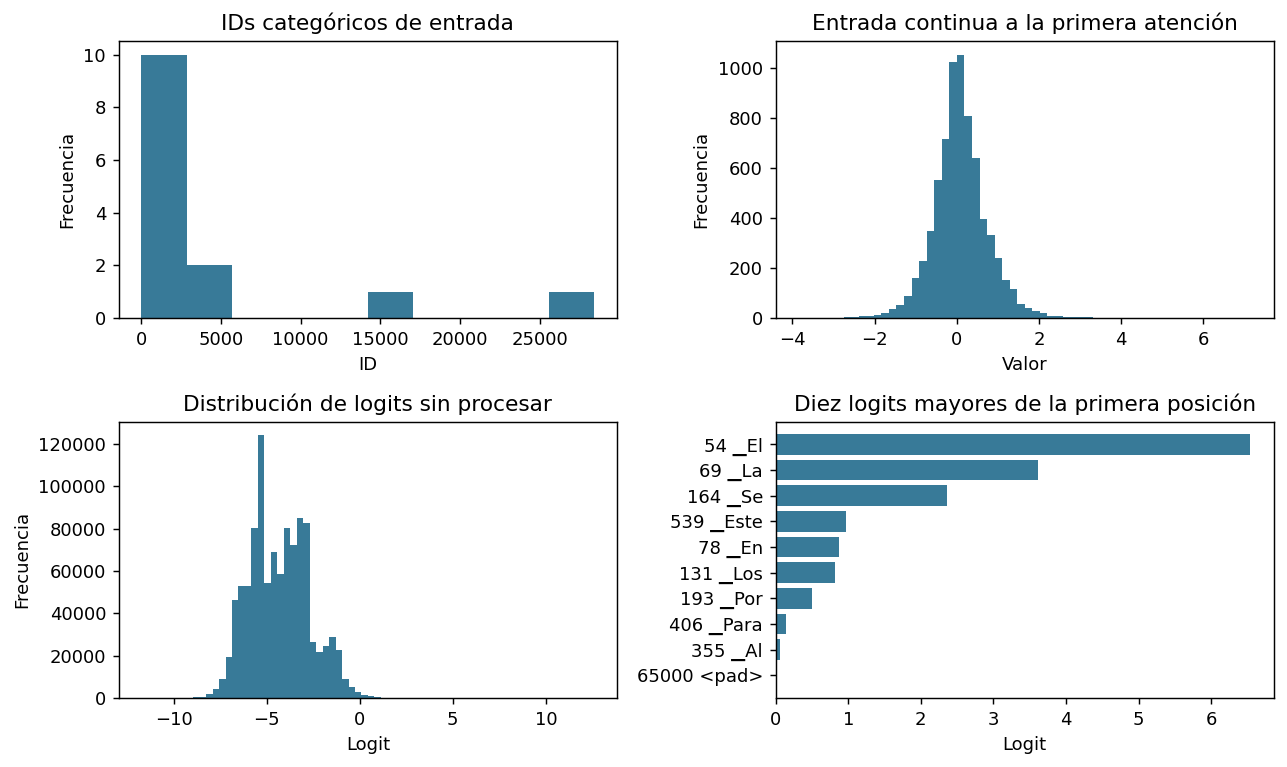

Ejemplo 1 logits {'shape': [1, 16, 65001], 'dtype': 'float32', 'device': 'cpu', 'n': 1040016, 'min': -11.726377487182617, 'max': 12.611454010009766, 'mean': -4.307820500530554, 'std_population': 1.6181738346993788, 'percentiles': {'p0': -11.726377487182617, 'p25': -5.507368445396423, 'p50': -4.397312879562378, 'p75': -3.090337097644806, 'p100': 12.611454010009766}} primera posición [{'id': 54, 'token': '▁El', 'logit': 6.536732196807861, 'probability': 0.7982265678642917}, {'id': 69, 'token': '▁La', 'logit': 3.608137369155884, 'probability': 0.04268286916110766}, {'id': 164, 'token': '▁Se', 'logit': 2.361994504928589, 'probability': 0.012276106165086276}]
Control softmax: finitos True error máximo 1.1879386363489175e-14 suma [[0.9999999999999939, 0.9999999999999984, 1.0000000000000016, 1.00000000000001, 0.9999999999999979, 0.9999999999999881, 1.0000000000000075, 0.9999999999999974, 1.0000000000000098, 0.9999999999999954, 0.9999999999999973, 0.9999999999999956, 1.0000000000000058, 1.0000

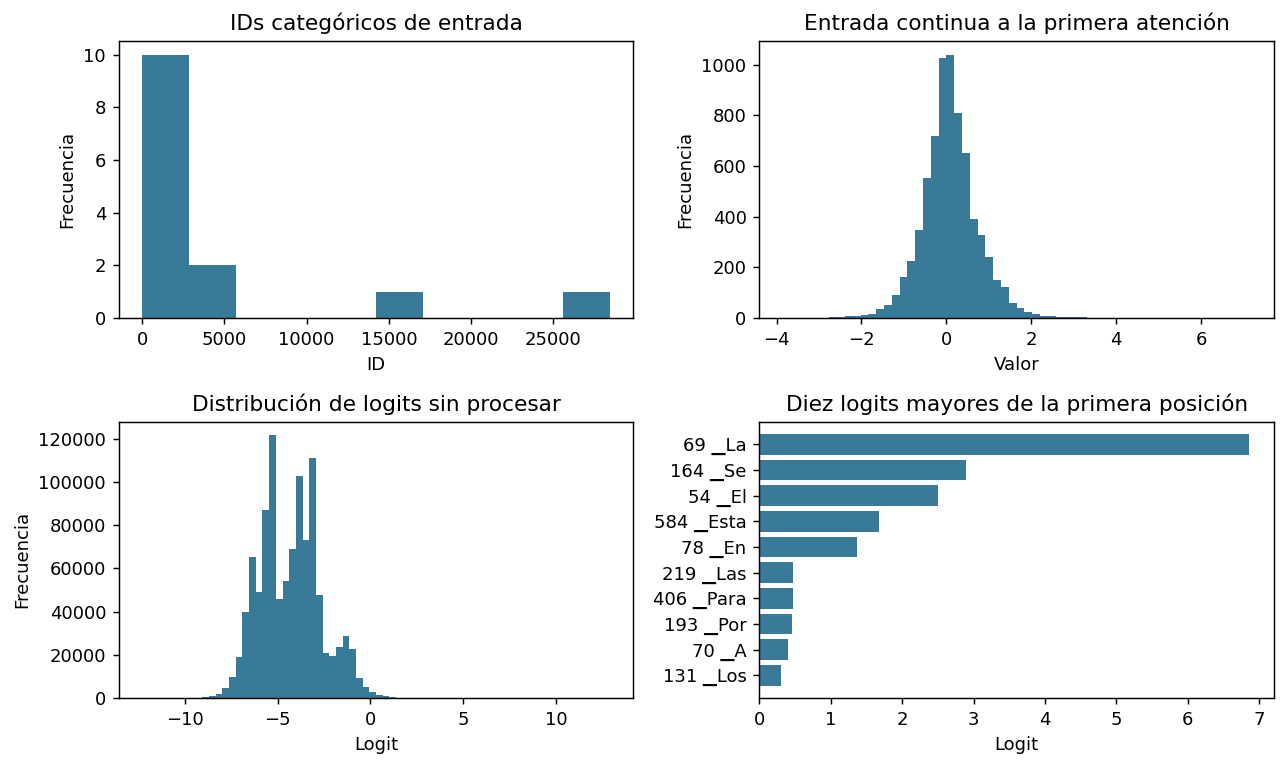

Ejemplo 2 logits {'shape': [1, 16, 65001], 'dtype': 'float32', 'device': 'cpu', 'n': 1040016, 'min': -12.30068302154541, 'max': 12.911893844604492, 'mean': -4.295522956881335, 'std_population': 1.667931527415714, 'percentiles': {'p0': -12.30068302154541, 'p25': -5.537959933280945, 'p50': -4.240214824676514, 'p75': -3.098488211631775, 'p100': 12.911893844604492}} primera posición [{'id': 69, 'token': '▁La', 'logit': 6.864116668701172, 'probability': 0.8389375362068116}, {'id': 164, 'token': '▁Se', 'logit': 2.8958592414855957, 'probability': 0.015861246803343464}, {'id': 54, 'token': '▁El', 'logit': 2.4977784156799316, 'probability': 0.010652536154567743}]


In [19]:
for i,(r,(out,emb,step_logits)) in enumerate(zip(results,all_outputs),1):
    z = out.logits
    softmax32_error = float((z.softmax(-1).sum(-1)-1).abs().max())
    p = z.double().softmax(-1)
    assert z.shape == (1,len(r['generated_ids'][0])-1,c.vocab_size)
    print('Control softmax:', 'finitos',bool(torch.isfinite(p).all()),
          'error máximo',float((p.sum(-1)-1).abs().max()), 'suma',p.sum(-1).tolist())
    assert torch.isfinite(p).all() and torch.allclose(p.sum(-1),torch.ones_like(p.sum(-1)),atol=1e-12,rtol=0)
    first = z[0,0]
    top = torch.topk(p[0,0],10).indices
    rows = [dict(id=int(j),token=tokenizer.convert_ids_to_tokens(int(j)),
                 logit=float(first[j]),probability=float(p[0,0,j])) for j in top]
    pd.DataFrame(rows).to_csv(OUT/f'e{i}_top10.csv',index=False)
    pd.DataFrame(dict(id=np.arange(c.vocab_size),logit=first.numpy(),
                      probability=p[0,0].numpy())).to_csv(OUT/f'e{i}_logits_primera_posicion.csv',index=False)
    r.update(logits_stats=describe(z),first_logits_stats=describe(first),top10=rows,
             raw_first_argmax=int(first.argmax()),selected_first=r['generated_ids'][0][1],
             softmax32_sum_max_error=softmax32_error,
             probability_sum_max_error=float((p.sum(-1)-1).abs().max()))
    fig,ax = plt.subplots(2,2,figsize=(10,6))
    ax[0,0].hist(np.asarray(r['ids']).ravel(),bins=min(10,len(r['tokens'])),color='#387a98')
    ax[0,0].set(title='IDs categóricos de entrada',xlabel='ID',ylabel='Frecuencia')
    ax[0,1].hist(emb.numpy().ravel(),bins=60,color='#387a98')
    ax[0,1].set(title='Entrada continua a la primera atención',xlabel='Valor',ylabel='Frecuencia')
    ax[1,0].hist(z.numpy().ravel(),bins=70,color='#387a98',label='Todas las posiciones')
    ax[1,0].set(title='Distribución de logits sin procesar',xlabel='Logit',ylabel='Frecuencia')
    ax[1,1].barh([f"{x['id']} {x['token']}" for x in rows][::-1],
                [x['logit'] for x in rows][::-1],color='#387a98')
    ax[1,1].set(title='Diez logits mayores de la primera posición',xlabel='Logit')
    figure_save(f'e{i}_distribuciones.png')
    print('Ejemplo',i,'logits',r['logits_stats'],'primera posición',rows[:3])

## 10 Obtención de pesos de self attention
**Objetivo:** comprobar atención del encoder, decoder y cruzada. Los pesos A son
softmax(QK^T/sqrt(d_k)+M); la activación contextual es AV. Se reconstruye Q,K,V
de la primera capa del encoder con sus proyecciones aprendidas y se valida A.
**Verificación:** dimensiones, finitud, no negatividad, suma uno y ceros causales.
**Interpretación:** los pesos no son los parámetros W_Q,W_K,W_V ni las activaciones AV.

In [20]:
attention_rows = []
for i,(r,(out,emb,step_logits)) in enumerate(zip(results,all_outputs),1):
    s,t = len(r['tokens']),len(r['decoder_tokens'])
    types = dict(encoder=out.encoder_attentions,decoder=out.decoder_attentions,cross=out.cross_attentions)
    arrays = dict(input_ids=np.asarray(r['ids']),attention_mask=np.asarray(r['mask']),
                  encoder_input=emb.numpy(),decoder_input_ids=np.asarray(r['decoder_input_ids']),
                  generated_ids=np.asarray(r['generated_ids']),logits=out.logits.numpy(),
                  generation_logits=step_logits.numpy(),
                  encoder_final=out.encoder_last_hidden_state.numpy(),
                  decoder_final=out.decoder_hidden_states[-1].numpy())
    checks = {}
    for kind, layers in types.items():
        a = torch.stack(layers)
        n = c.encoder_layers if kind == 'encoder' else c.decoder_layers
        h = c.encoder_attention_heads if kind == 'encoder' else c.decoder_attention_heads
        q,k = (s,s) if kind == 'encoder' else ((t,t) if kind == 'decoder' else (t,s))
        assert a.shape == (n,1,h,q,k)
        assert torch.isfinite(a).all() and a.min() >= 0
        row_error = float((a.sum(-1)-1).abs().max())
        assert row_error < 1e-5
        future = float(torch.triu(a,diagonal=1).abs().max()) if kind == 'decoder' else None
        if future is not None:
            assert future < 1e-7
        checks[kind] = dict(shape=list(a.shape),row_sum_max_error=row_error,future_max=future)
        arrays[kind+'_attention'] = a.numpy()
        for li in range(n):
            for hi in range(h):
                m = a[li,0,hi]
                entropy = -(m*m.clamp_min(1e-30).log()).sum(-1)
                # Normalizar por el número de claves accesibles; la primera fila causal vale 0.
                denom = torch.arange(1,q+1,dtype=torch.float32).log() if kind=='decoder' else torch.full((q,),float(np.log(k)))
                norm = torch.where(denom>0,entropy/denom.clamp_min(1e-30),torch.zeros_like(entropy))
                incoming = m.mean(0)
                key_tokens = r['decoder_tokens'] if kind=='decoder' else r['tokens']
                j = int(incoming.argmax())
                attention_rows.append(dict(example=i,kind=kind,layer=li+1,head=hi+1,
                    entropy=float(entropy.mean()),normalized_entropy=float(norm.mean()),
                    diagonal_mean=float(m.diag().mean()) if q==k and kind!='cross' else None,
                    top_key_position=j,top_key_token=key_tokens[j],top_key_mass=float(incoming[j])))
    attn = model.model.encoder.layers[0].self_attn
    h,d = c.encoder_attention_heads,c.d_model//c.encoder_attention_heads
    with torch.inference_mode():
        split = lambda x:x.view(1,s,h,d).transpose(1,2)
        Q,K,V = split(attn.q_proj(emb)),split(attn.k_proj(emb)),split(attn.v_proj(emb))
        A = (Q @ K.transpose(-1,-2) / np.sqrt(d)).softmax(-1)
        AV = A @ V
        err = float((A-out.encoder_attentions[0]).abs().max())
        assert err < 1e-5
    arrays.update(Q=Q.numpy(),K=K.numpy(),V=V.numpy(),AV=AV.numpy())
    r.update(attention_checks=checks,qkv_shape=list(Q.shape),av_shape=list(AV.shape),
             attention_reconstruction_error=err)
    np.savez_compressed(OUT/f'e{i}_tensores.npz',**arrays)
    print('Ejemplo',i,checks,'error reconstrucción',err)
metrics = pd.DataFrame(attention_rows)
metrics.to_csv(OUT/'metricas_atencion.csv',index=False)

Ejemplo 1 {'encoder': {'shape': [6, 1, 8, 14, 14], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': None}, 'decoder': {'shape': [6, 1, 8, 16, 16], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': 0.0}, 'cross': {'shape': [6, 1, 8, 16, 14], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': None}} error reconstrucción 0.0
Ejemplo 2 {'encoder': {'shape': [6, 1, 8, 14, 14], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': None}, 'decoder': {'shape': [6, 1, 8, 16, 16], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': 0.0}, 'cross': {'shape': [6, 1, 8, 16, 14], 'row_sum_max_error': 2.384185791015625e-07, 'future_max': None}} error reconstrucción 0.0


## 11 Generación de mapas de calor
**Objetivo:** comparar capas inicial y final, cabezas 1 y 2, seleccionadas antes
de observar los resultados. Filas = consultas; columnas = claves. Se conserva la
misma escala 0 a 1 y se muestran tokens especiales y subpalabras.
**Verificación:** cuatro mapas por tipo y ejemplo, con ejes legibles.
**Interpretación:** decoder es triangular por construcción; encoder no tiene esa
restricción. Atención cruzada enlaza destino y fuente, pero no es self-attention.

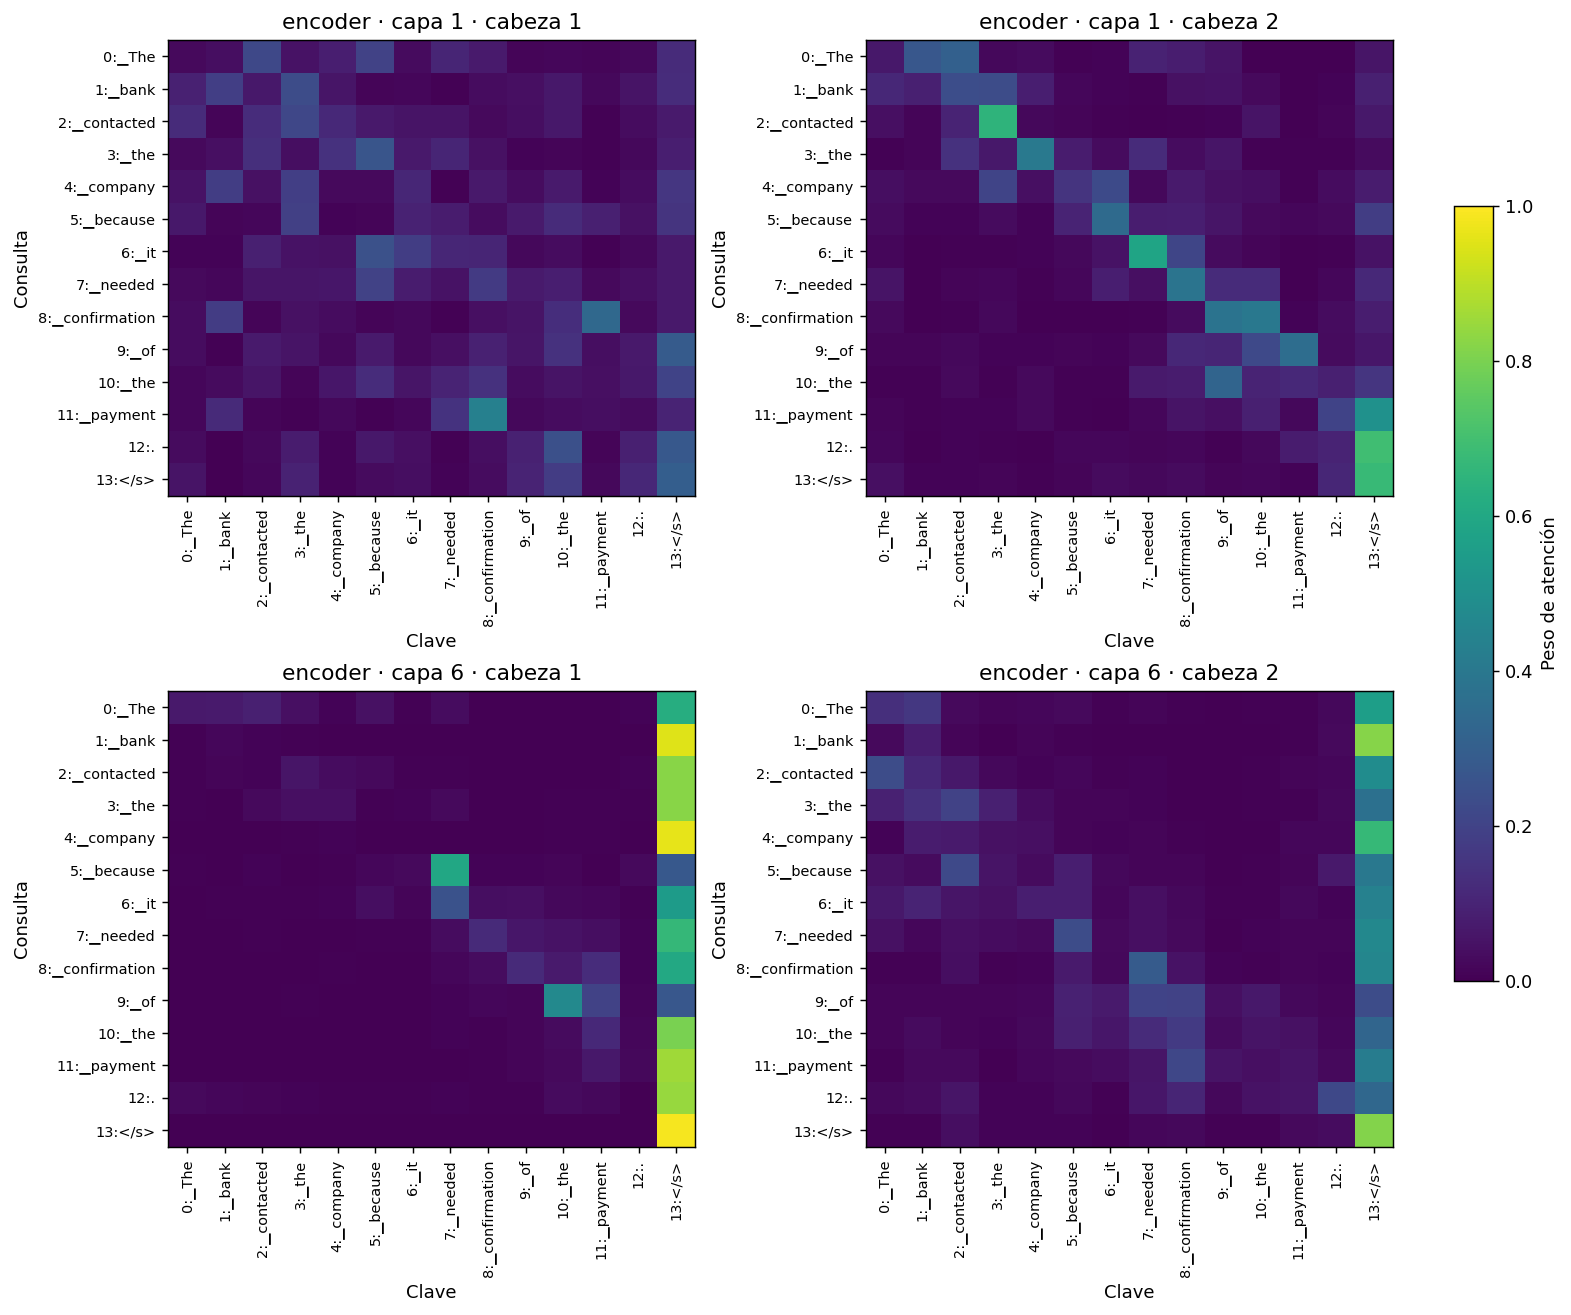

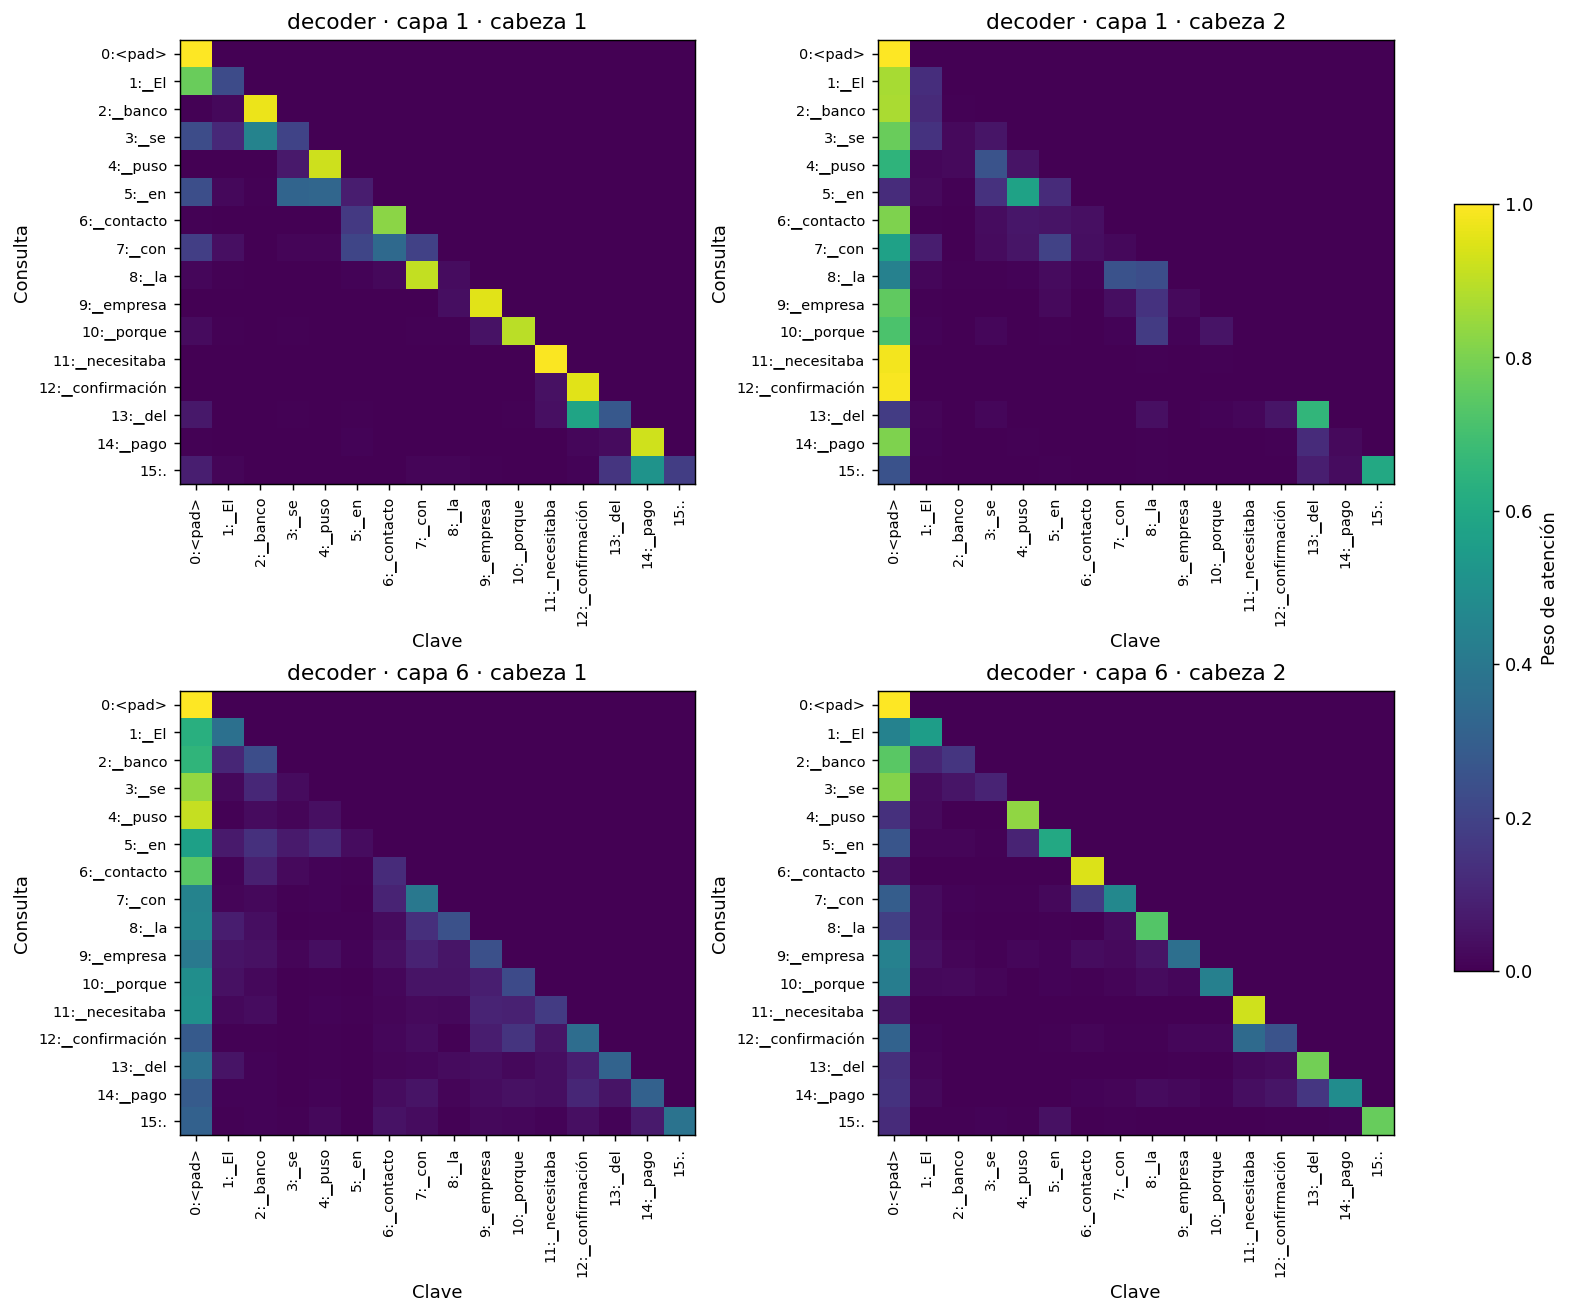

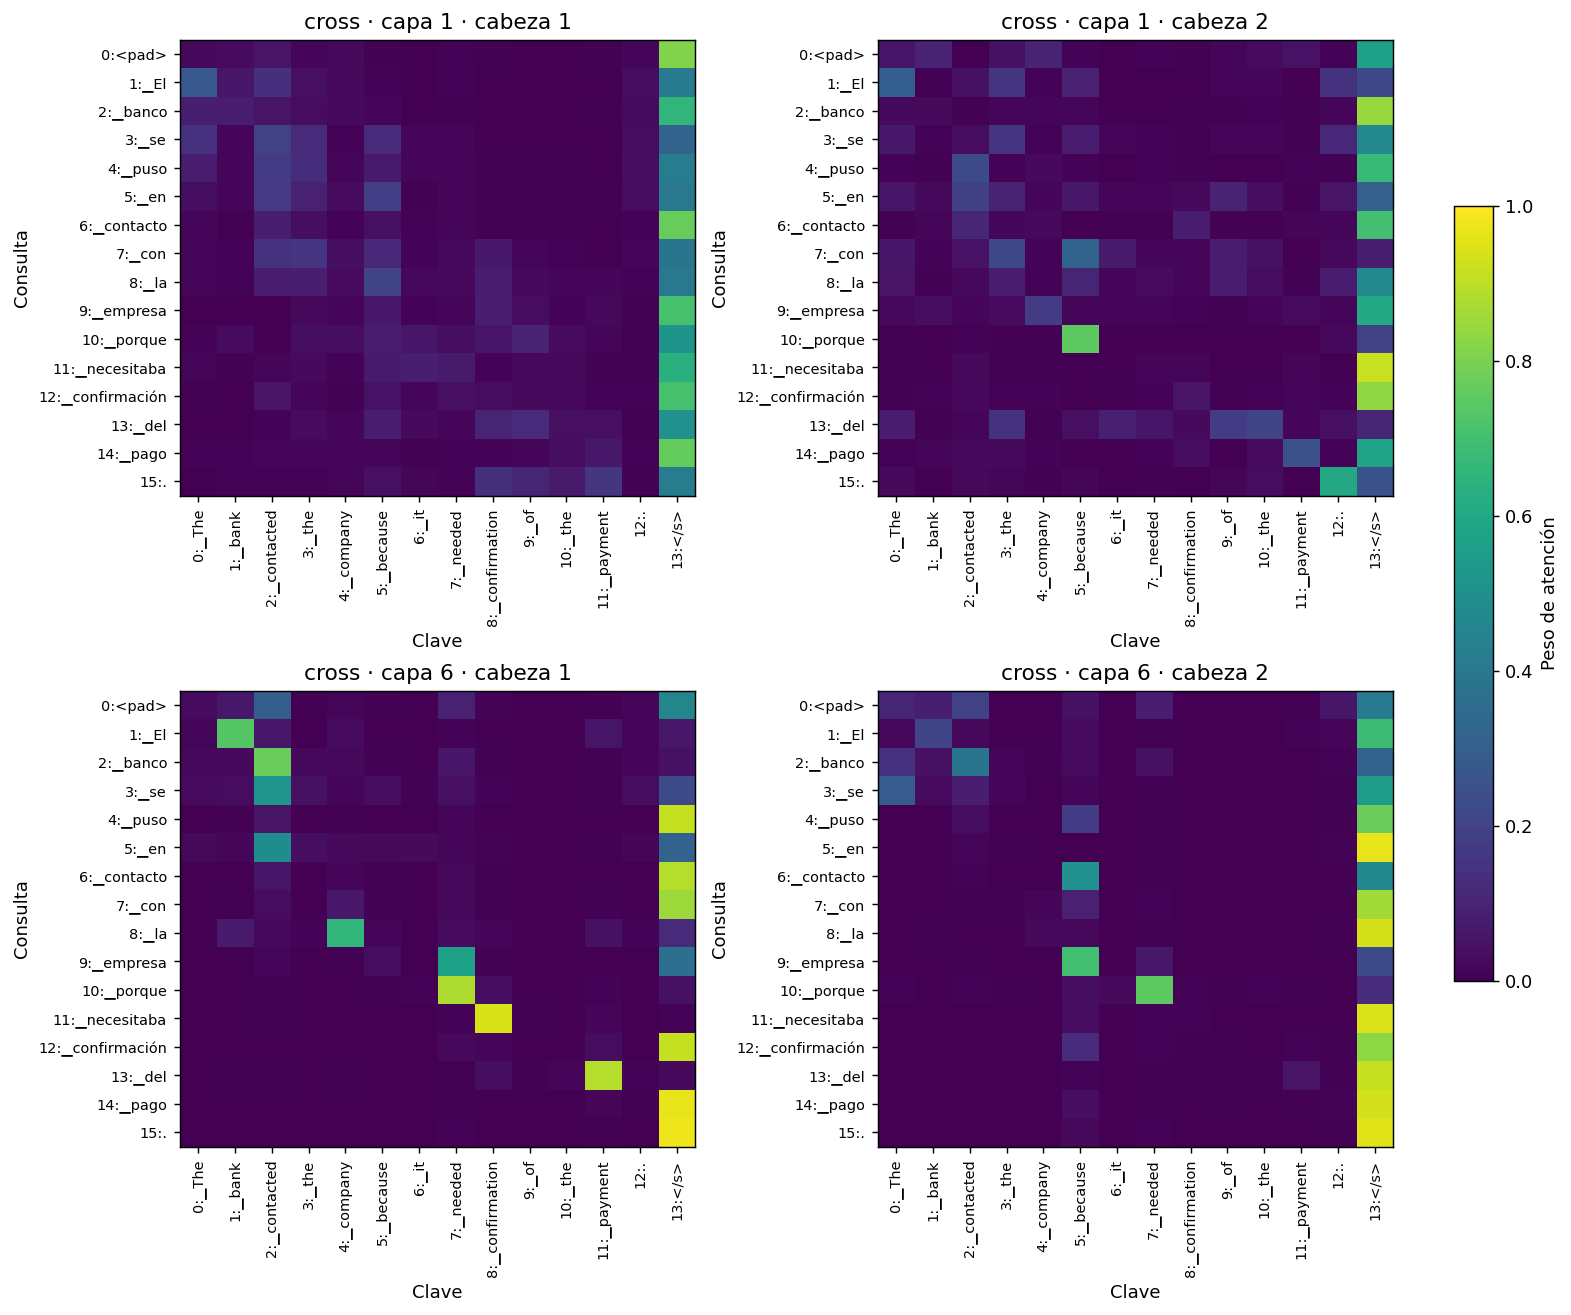

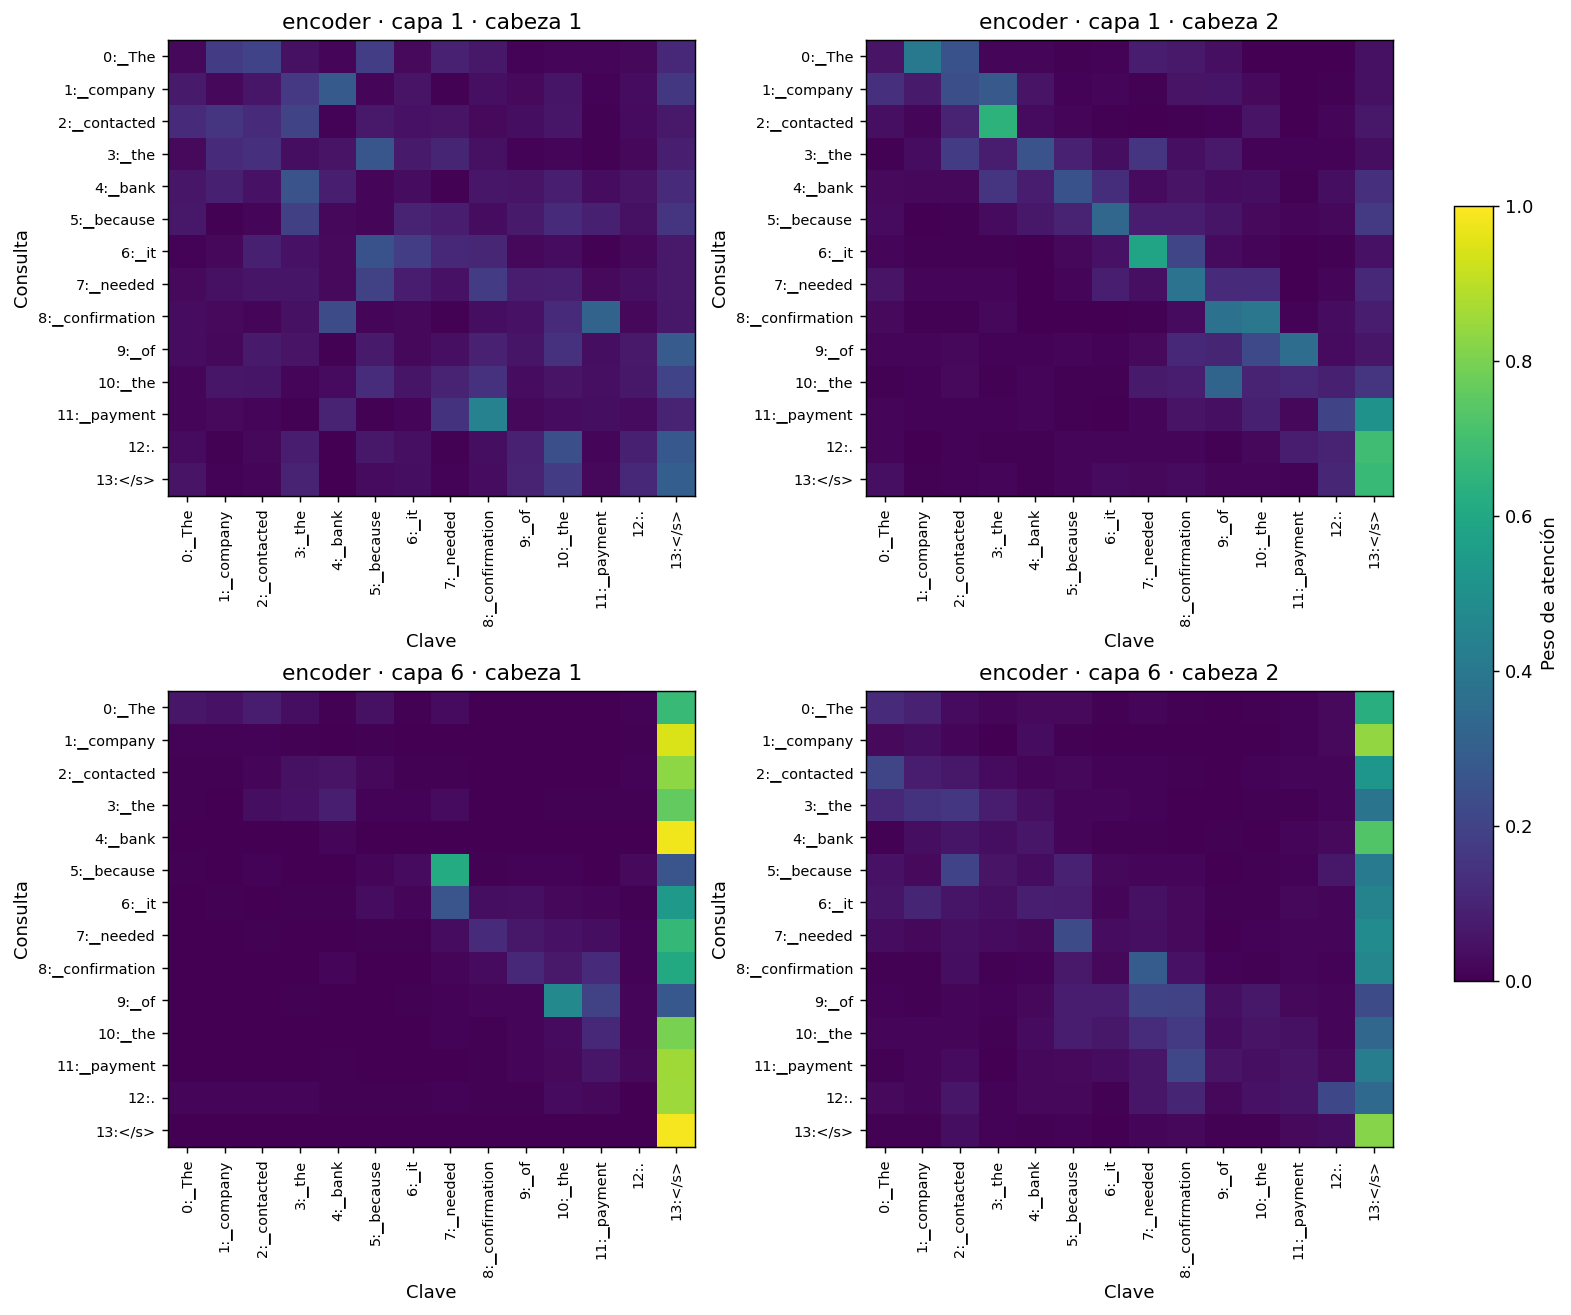

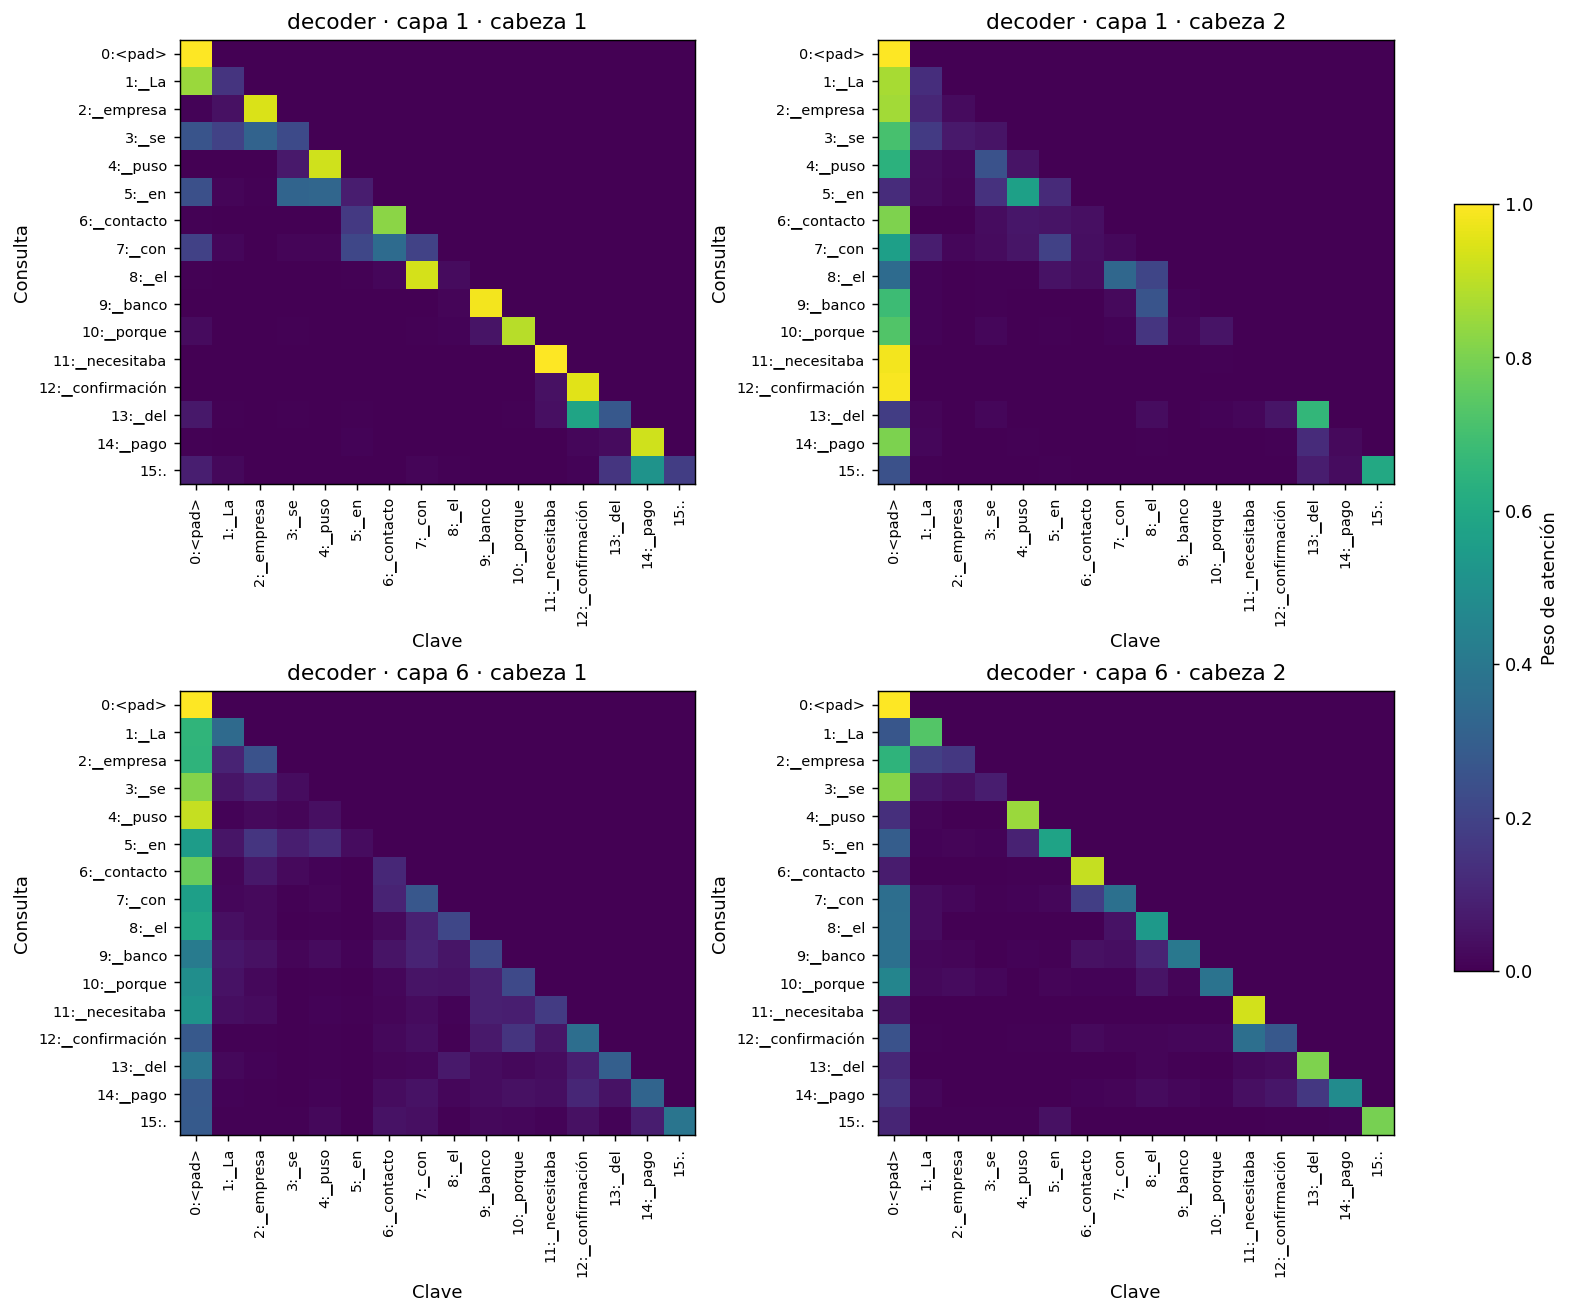

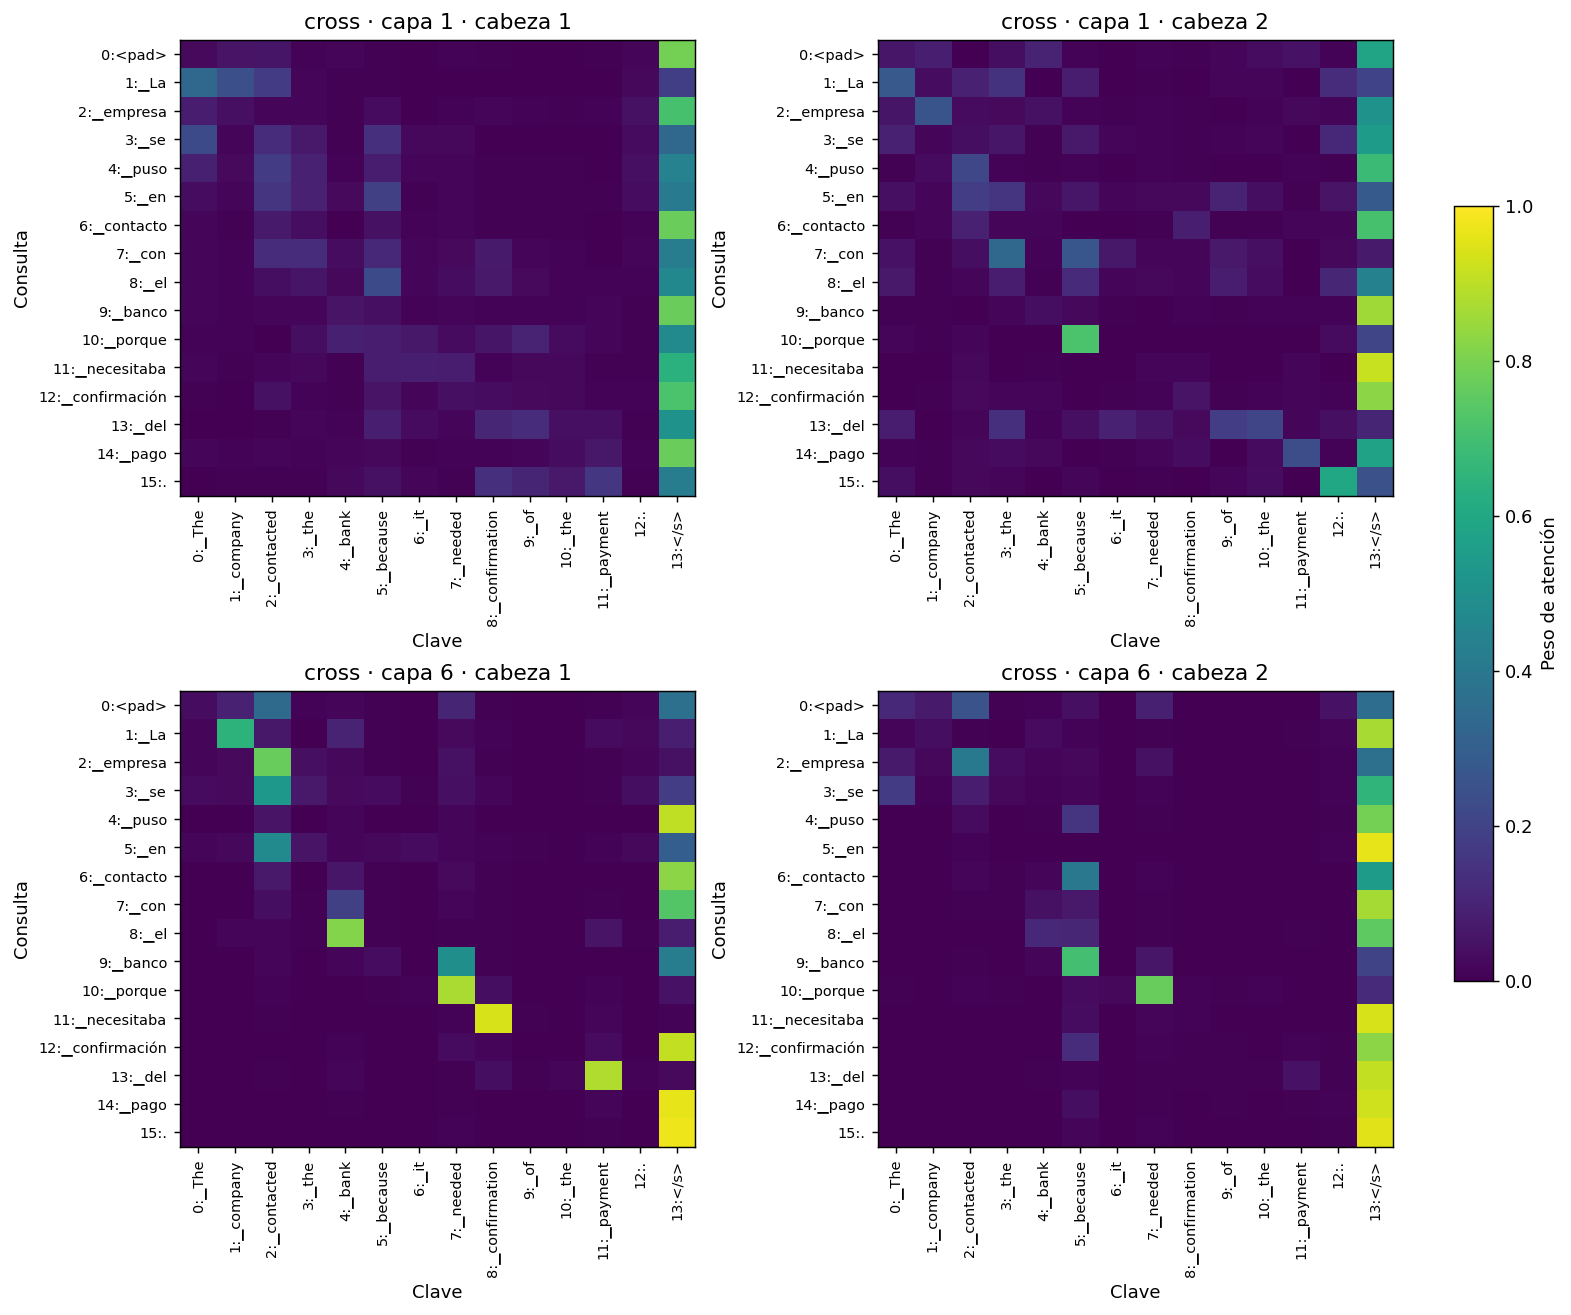

In [21]:
for i,(r,(out,emb,step_logits)) in enumerate(zip(results,all_outputs),1):
    for kind,layers in [('encoder',out.encoder_attentions),('decoder',out.decoder_attentions),('cross',out.cross_attentions)]:
        fig,axes = plt.subplots(2,2,figsize=(12,10),layout='constrained')
        xt = r['decoder_tokens'] if kind=='decoder' else r['tokens']
        yt = r['tokens'] if kind=='encoder' else r['decoder_tokens']
        for ax,(li,hi) in zip(axes.flat,[(0,0),(0,1),(len(layers)-1,0),(len(layers)-1,1)]):
            im = ax.imshow(layers[li][0,hi].numpy(),vmin=0,vmax=1,cmap='viridis',aspect='auto')
            ax.set_xticks(range(len(xt)),[f'{j}:{x}' for j,x in enumerate(xt)],rotation=90,fontsize=8)
            ax.set_yticks(range(len(yt)),[f'{j}:{x}' for j,x in enumerate(yt)],fontsize=8)
            ax.set(title=f'{kind} · capa {li+1} · cabeza {hi+1}',xlabel='Clave',ylabel='Consulta')
        fig.colorbar(im,ax=axes.ravel().tolist(),label='Peso de atención',shrink=.7)
        plt.savefig(OUT/f'e{i}_{kind}_atencion.png',bbox_inches='tight')
        plt.show()
        plt.close()

### Activaciones contextuales AV para los dos ejemplos
A contiene pesos normalizados; AV combina los valores y puede tener signos.
Se representa la primera cabeza de la primera capa del encoder, con escala común.
Verificación: AV coincide con el producto A por V y todos sus valores son finitos.
Los canales no tienen etiquetas semánticas; sus máximos no explican causalidad.

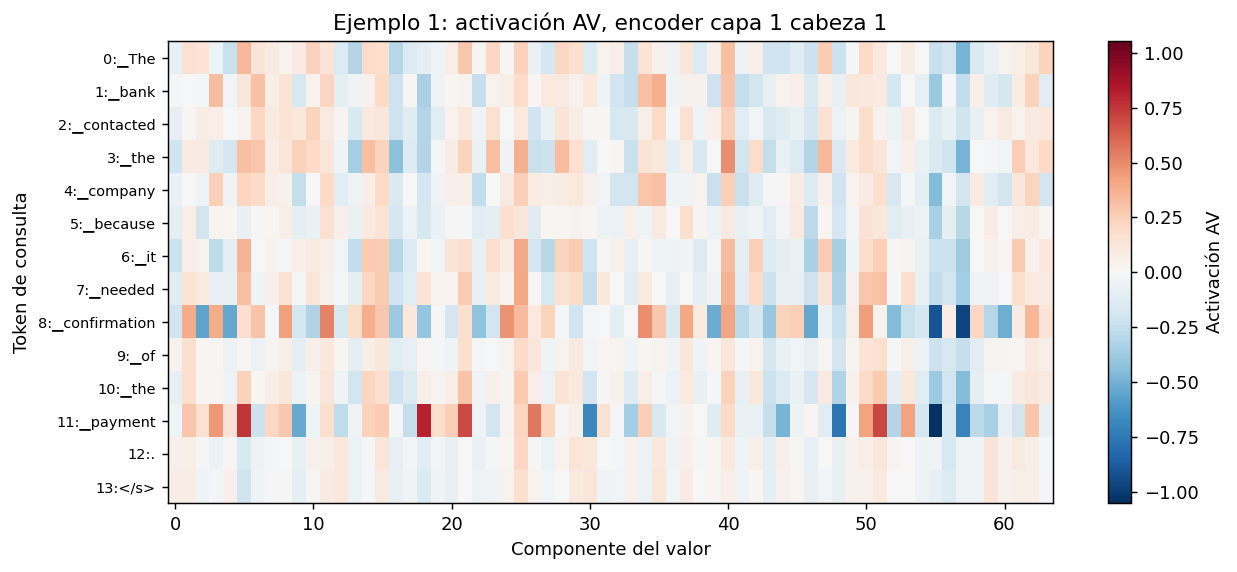

Ejemplo 1 AV {'shape': [14, 64], 'dtype': 'float32', 'device': 'cpu', 'n': 896, 'min': -1.052249550819397, 'max': 0.8097551465034485, 'mean': 0.0016409891733084286, 'std_population': 0.18926838619001862, 'percentiles': {'p0': -1.052249550819397, 'p25': -0.08922070264816284, 'p50': 0.007880343357101083, 'p75': 0.09938979707658291, 'p100': 0.8097551465034485}}


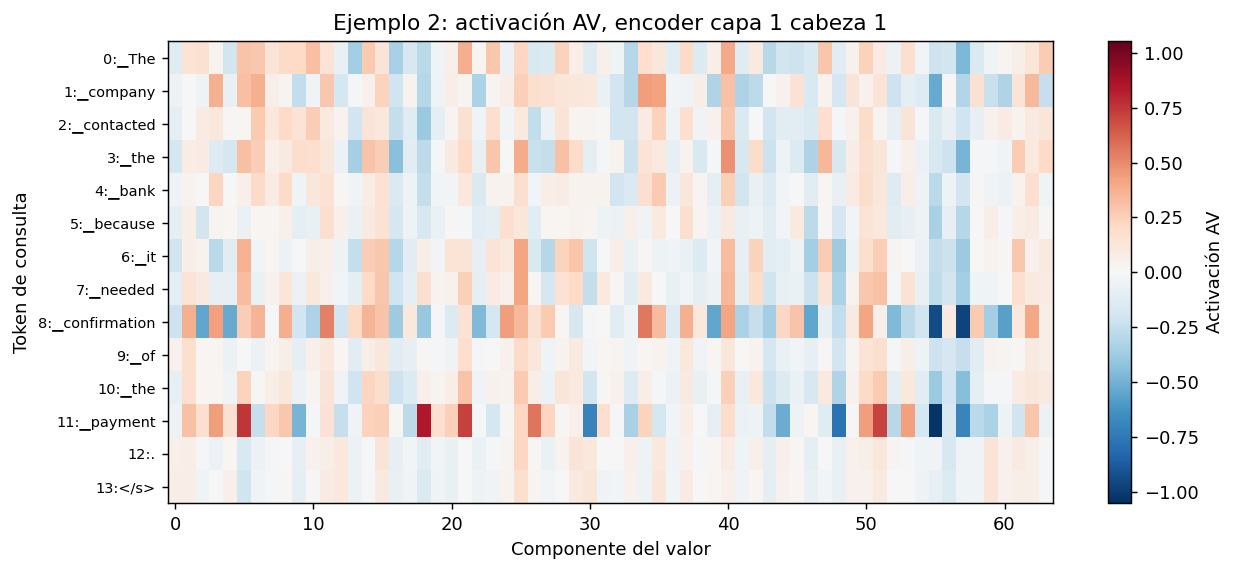

Ejemplo 2 AV {'shape': [14, 64], 'dtype': 'float32', 'device': 'cpu', 'n': 896, 'min': -1.0281219482421875, 'max': 0.843599796295166, 'mean': 0.0024940108509749087, 'std_population': 0.19521633272889444, 'percentiles': {'p0': -1.0281219482421875, 'p25': -0.0868622474372387, 'p50': 0.009115809574723244, 'p75': 0.10833412781357765, 'p100': 0.843599796295166}}


In [24]:
datasets = [np.load(OUT/f'e{i}_tensores.npz',allow_pickle=False) for i in [1,2]]
limit = max(float(np.abs(a['AV'][0,0]).max()) for a in datasets)
for i,(a,r) in enumerate(zip(datasets,results),1):
    av = a['AV'][0,0]
    assert np.allclose(a['encoder_attention'][0,0,0] @ a['V'][0,0],av,atol=1e-6)
    assert np.isfinite(av).all()
    r['av_head1_stats'] = describe(av)
    fig,ax = plt.subplots(figsize=(10,4.5))
    im = ax.imshow(av,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
    ax.set_yticks(range(len(r['tokens'])),[f'{j}:{t}' for j,t in enumerate(r['tokens'])],fontsize=8)
    ax.set(title=f'Ejemplo {i}: activación AV, encoder capa 1 cabeza 1',xlabel='Componente del valor',ylabel='Token de consulta')
    fig.colorbar(im,ax=ax,label='Activación AV')
    figure_save(f'e{i}_AV.png')
    print('Ejemplo',i,'AV',r['av_head1_stats'])
for a in datasets: a.close()

## 12 Comparación entre los dos ejemplos
**Objetivo:** resumir atención recibida, concentración y cambios con el contexto.
La masa recibida es la media sobre consultas por posición clave. La entropía media
normalizada usa log(número de claves accesibles); cero implica concentración.
En decoder las claves tempranas tienen más oportunidades de recibir atención.

**Verificación:** métricas para todas las capas y cabezas, no sólo las dibujadas.

**Interpretación:** diferencias de tokenización o longitud dificultan comparar matrices
elemento a elemento; se comparan estadísticas y posiciones identificadas explícitamente.

 example    kind  layer  head  entropy  normalized_entropy  diagonal_mean  top_key_position top_key_token  top_key_mass
       1 encoder      1     1 2.240536            0.848991       0.086820                13          </s>      0.148382
       1 encoder      1     2 1.771898            0.671413       0.112228                13          </s>      0.202136
       1 encoder      6     1 0.888917            0.336831       0.096025                13          </s>      0.717394
       1 encoder      6     2 1.668566            0.632258       0.127300                13          </s>      0.485985
       1 decoder      1     1 0.630855            0.343303       0.603245                 0         <pad>      0.165841
       1 decoder      1     2 0.768723            0.399789       0.189369                 0         <pad>      0.674408
       1 decoder      6     1 1.218107            0.599603       0.280212                 0         <pad>      0.556940
       1 decoder      6     2 0.871348  

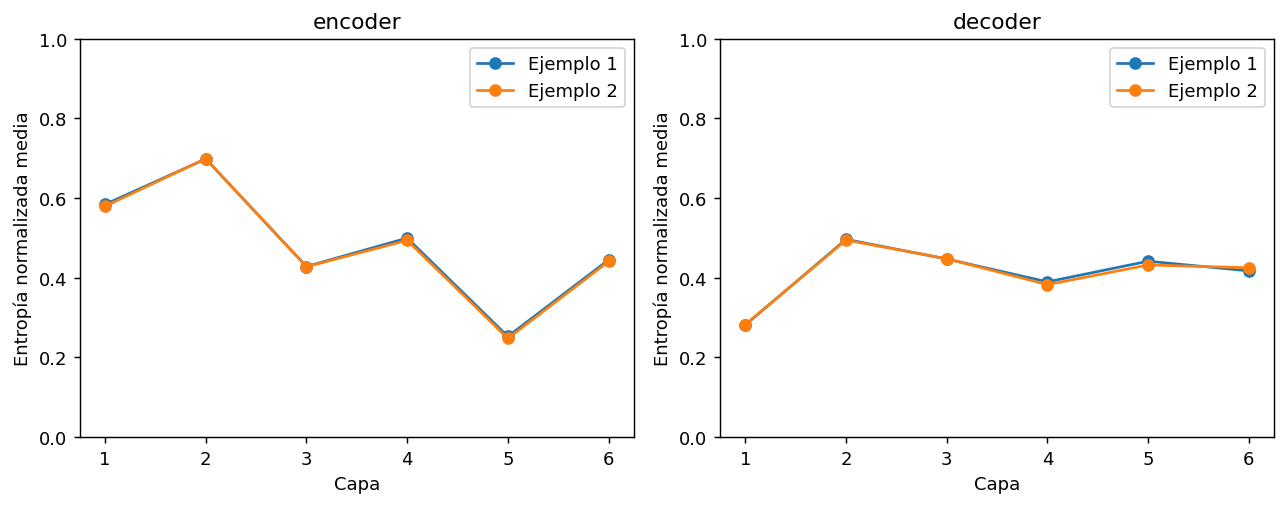

In [25]:
selected = metrics[(metrics.layer.isin([1,c.encoder_layers])) & (metrics['head'].isin([1,2]))]
print(selected.to_string(index=False))
selected.to_csv(OUT/'atencion_seleccionada.csv',index=False)
fig,axes = plt.subplots(1,2,figsize=(10,4))
for ax,kind in zip(axes,['encoder','decoder']):
    for example in [1,2]:
        group = metrics[(metrics.example==example)&(metrics.kind==kind)].groupby('layer').normalized_entropy.mean()
        ax.plot(group.index,group.values,marker='o',label=f'Ejemplo {example}')
    ax.set(title=kind,xlabel='Capa',ylabel='Entropía normalizada media',ylim=(0,1))
    ax.legend()
figure_save('comparacion_entropia.png')

## 13 Resultados discusión y conclusiones
**Objetivo:** cerrar la cadena de evidencia. Se exporta un registro consolidado y
hashes de los archivos para detectar modificaciones.

**Verificación:** todas las
aserciones anteriores deben pasar; `validacion.json` sólo se escribe al finalizar.

**Interpretación:** triangularidad es evidencia de la máscara, no aprendizaje
sintáctico. La atención bidireccional permite contexto a ambos lados. Las métricas
describen estos dos casos; sin ablaciones no prueban causalidad ni calidad general.
El informe adjunto interpreta los valores efectivamente ejecutados.

In [26]:
save_json('resultados.json',results)
save_json('validacion.json',dict(status='PASS',examples=len(results),
    checks=['finite_inputs_logits_attention','parameter_count','vocabulary_bounds',
            'attention_shapes','probability_sums','attention_row_sums','causal_mask',
            'raw_logits_replay','greedy_token_consistency','QK_attention_reconstruction']))
manifest = {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.iterdir() if p.is_file() and p.name!='manifest_sha256.json'}
save_json('manifest_sha256.json',manifest)
for r in results:
    print(f"Ejemplo {r['example']}: {r['translation']} | logits {r['logits_stats']['shape']}")
print('Validación completa. Artefactos en',OUT.resolve())

Ejemplo 1: El banco se puso en contacto con la empresa porque necesitaba confirmación del pago. | logits [1, 16, 65001]
Ejemplo 2: La empresa se puso en contacto con el banco porque necesitaba confirmación del pago. | logits [1, 16, 65001]
Validación completa. Artefactos en /content/resultados
